# Notebook 5 - Predicting customer value

> **Mentor briefing** - the seven questions we answer for every phase.

| Question | Answer |
|---|---|
| **1. What are we doing?** | Train five classifiers to predict, today, which customers will be in the top 20% by spend over the **next 90 days**. |
| **2. Why?** | Segmentation describes the past; prediction lets marketing act *before* value is realised. |
| **3. Real-world problem it solves** | Where should the retention budget go? Contact the customers most likely to spend a lot next quarter. |
| **4. What does the code do?** | Builds three time-separated datasets (train/validation/test), tunes five models on validation data, picks one by a documented business rule, then scores the untouched test period once. |
| **5. Expected output** | A comparison table, ROC/PR curves, a confusion matrix, feature importance. Expect good-but-not-perfect numbers (ROC-AUC mid-0.8s). |
| **6. What can go wrong?** | Leakage; random (non-temporal) splits; tuning on the test set; reporting accuracy on imbalanced data; trusting a single number. |
| **7. How do professionals approach this?** | They split by time, tune only on validation, choose a threshold from business costs, report several metrics and monitor drift after launch. |


## The design in one picture

```
 train cutoff T1 --90 days--> validation cutoff T2 --90 days--> test cutoff T3 --90 days--> end of data
 features: past < T1           features: past < T2               features: past < T3
 label:    spend in T1..T2     label:    spend in T2..T3         label:    spend in T3..end
```
* **Features** come only from *before* each cut-off. **Labels** come only from the 90 days *after* it.
* The model learns on T1, is **tuned and selected** on T2, and is judged **once** on T3.
* **Label rule (documented):** a customer is *high value* if their **net revenue in the next 90 days is in the top 20%** of customers known on the cut-off date (a per-window quantile keeps the share comparable between a quiet summer and a Christmas peak). Customers who do not buy again have revenue 0 and are labelled 0.
* The label is **not** one of the input features, so the model cannot cheat.

## Concepts
* **Classification** - predict a category (here: high value yes/no) as a probability.
* **Train / validation / test** - train = learn; validation = choose settings and the winning model; test = one final honest exam.
* **Overfitting** - memorising training noise: great on train, worse on new data. **Underfitting** - too simple to see the pattern: poor on both.
* **Cross-validation** - repeat train/validate on several slices to see how stable a score is. We report 5-fold CV on the *training* period as a sanity check; because time matters, selection uses the later validation window.
* **Precision** - of customers we flag, how many are truly high value? **Recall** - of all truly high-value customers, how many did we flag? **F1** - their harmonic mean.
* **ROC-AUC** - probability that a random high-value customer is scored above a random other one (0.5 = coin flip, 1 = perfect). **PR-AUC** is more informative when positives are rare.
* **Accuracy** can mislead: with 20% positives, saying "nobody is high value" is already 80% accurate.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                      # lets us import our own code from src/
from src.utils.config import get_paths, RANDOM_STATE
paths = get_paths(ROOT)

sns.set_theme(style="whitegrid", context="notebook", palette=["#2563eb", "#0d9488", "#4f46e5", "#eda100", "#eb6834", "#e87ba4"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (9, 4.2)})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 140
import itertools
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, ConfusionMatrixDisplay
from src.features.customer_features import FEATURE_COLUMNS
from src.models.value_prediction import make_windows, build_split, make_preprocessor, train_and_select
from src.models.rbf_network import RBFNetworkClassifier
clean = pd.read_parquet(paths.processed / "cleaned_transactions.parquet")

## 1. Build the three time windows

In [2]:
w = make_windows(clean)
print(pd.Series(w.as_dict()).to_frame("value").T.to_string())
train, val, test = (build_split(clean, c, w.horizon) for c in (w.train, w.val, w.test))
summary = pd.DataFrame({"cutoff": [w.train, w.val, w.test], "customers": [len(d) for d in (train, val, test)],
                        "positive rate": [d.high_value.mean() for d in (train, val, test)],
                        "GBP needed to be 'high value'": [d.attrs["threshold_gbp"] for d in (train, val, test)]}, index=["train", "validation", "test"])
summary

                     train                  val                 test                  end horizon_days
value  2011-03-15 00:00:00  2011-06-13 00:00:00  2011-09-11 00:00:00  2011-12-10 00:00:00           90


,cutoff,customers,positive rate,GBP needed to be 'high value'
train,2011-03-15,4588,0.20,363.28
validation,2011-06-13,4952,0.20,317.82
test,2011-09-11,5256,0.20,581.20


The GBP threshold is higher in the test window - it is the Christmas quarter, so everybody spends more. That is exactly why the label is a *quantile* (top 20%) and not a fixed amount. Note this is a **distribution shift**: models trained on a quiet quarter must still work in the peak.

In [3]:
# Leakage audit: nothing derived from the future may be a feature
assert "future_revenue" not in FEATURE_COLUMNS and "high_value" not in FEATURE_COLUMNS
print("features given to the model:", FEATURE_COLUMNS)
print("correlation of each feature with the label (train):")
train[FEATURE_COLUMNS + ["high_value"]].corr(method="spearman")["high_value"].drop("high_value").sort_values(ascending=False).round(2).to_frame("spearman")

features given to the model: ['recency_days', 'frequency', 'monetary', 'avg_order_value', 'total_items', 'product_diversity', 'active_months', 'avg_basket_size', 'spend_30d', 'spend_60d', 'spend_90d', 'avg_days_between_purchases', 'tenure_days', 'return_rate']
correlation of each feature with the label (train):


,spearman
monetary,0.47
total_items,0.47
active_months,0.42
frequency,0.42
spend_90d,0.40
spend_60d,0.38
product_diversity,0.36
avg_order_value,0.32
spend_30d,0.31
return_rate,0.22


No feature is *suspiciously* perfect (a correlation near 1 would be a leakage alarm). Recent spend and monetary value predict the future moderately - as common sense says.

## 2. Underfitting vs overfitting - see it with your own eyes
A random forest with `max_depth` from 1 (too simple) to 25 (very flexible). Watch train vs validation ROC-AUC.

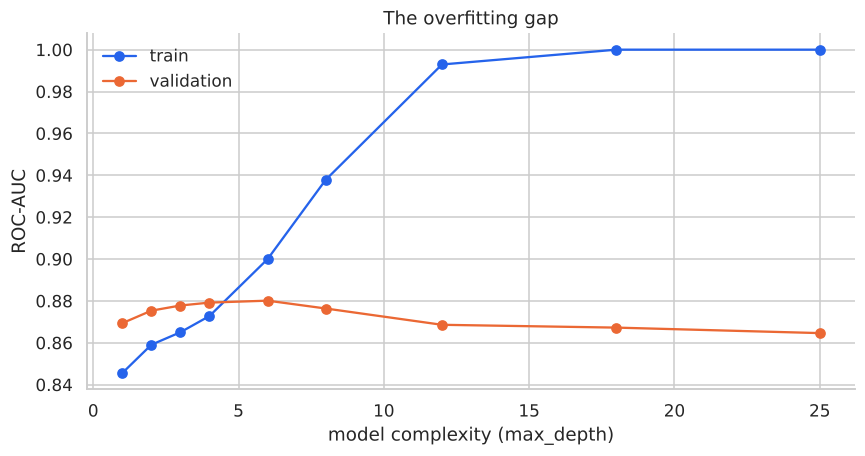

,max_depth,train AUC,validation AUC
0,1,0.85,0.87
1,2,0.86,0.88
2,3,0.86,0.88
3,4,0.87,0.88
4,6,0.90,0.88
5,8,0.94,0.88
6,12,0.99,0.87
7,18,1.00,0.87
8,25,1.00,0.86


In [4]:
prep = make_preprocessor().fit(train[FEATURE_COLUMNS])
Xtr, Xva = prep.transform(train[FEATURE_COLUMNS]), prep.transform(val[FEATURE_COLUMNS])
rows = []
for d in [1, 2, 3, 4, 6, 8, 12, 18, 25]:
    rf = RandomForestClassifier(n_estimators=150, max_depth=d, min_samples_leaf=1, random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, train.high_value)
    rows.append({"max_depth": d, "train AUC": roc_auc_score(train.high_value, rf.predict_proba(Xtr)[:, 1]), "validation AUC": roc_auc_score(val.high_value, rf.predict_proba(Xva)[:, 1])})
gap = pd.DataFrame(rows)
fig, ax = plt.subplots(); ax.plot(gap.max_depth, gap["train AUC"], "o-", label="train", color="#2563eb"); ax.plot(gap.max_depth, gap["validation AUC"], "o-", label="validation", color="#eb6834")
ax.set(xlabel="model complexity (max_depth)", ylabel="ROC-AUC", title="The overfitting gap"); ax.legend(frameon=False); plt.show()
gap.round(3)

Left: both curves low = **underfitting**. Right: train near 1.0 while validation stalls or drops = **overfitting** (the gap). We want the validation curve's peak, which is what tuning on validation data finds.

## 3. Train, tune and compare five models
`train_and_select` does everything in one reproducible call (this is the same code the pipeline uses):

| Model | Idea |
|---|---|
| Logistic Regression | a weighted sum of features turned into a probability; fast, explainable baseline |
| Random Forest | hundreds of decision trees voting |
| XGBoost | trees built one after another, each fixing the last one's errors |
| **RBF Network** | hidden neurons = prototype customers; each measures closeness with a Gaussian; a logistic output layer combines them |
| MLP Classifier | a standard feed-forward neural network |

Hyper-parameters (tree depth, `gamma`, `C` ...) are searched on the **validation** set; the decision threshold is the one that maximises F1 on validation; the **test** period is only scored afterwards.

In [5]:
res = train_and_select(clean, fast=False)
metrics = res["metrics"]
print("SELECTED:", metrics["selected_model"]); print("RULE    :", metrics["selection_rule"])
cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
table = lambda split: pd.DataFrame({n: {c: r[split][c] for c in cols} for n, r in metrics["models"].items()}).T
print("\nVALIDATION (used to choose)"); display(table("validation"))
print("TEST (touched once)");       display(table("test"))

2026-11-15 02:46:18,822 | INFO    | src.models.value_prediction | Split sizes train/val/test = 4588/4952/5256 | positive rates 0.20/0.20/0.20


2026-11-15 02:46:18,927 | INFO    | src.models.value_prediction | Logistic Regression  val PR-AUC 0.675 | test ROC-AUC 0.860


2026-11-15 02:46:30,199 | INFO    | src.models.value_prediction | Random Forest        val PR-AUC 0.702 | test ROC-AUC 0.860


2026-11-15 02:46:32,094 | INFO    | src.models.value_prediction | XGBoost              val PR-AUC 0.704 | test ROC-AUC 0.868


2026-11-15 02:46:36,259 | INFO    | src.models.value_prediction | RBF Network          val PR-AUC 0.692 | test ROC-AUC 0.864


2026-11-15 02:46:37,780 | INFO    | src.models.value_prediction | MLP Classifier       val PR-AUC 0.690 | test ROC-AUC 0.865


SELECTED: XGBoost
RULE    : highest validation PR-AUC among models with validation precision>=0.4 and recall>=0.5

VALIDATION (used to choose)


,accuracy,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.83,0.55,0.71,0.62,0.87,0.67
Random Forest,0.83,0.56,0.74,0.64,0.88,0.70
XGBoost,0.83,0.56,0.72,0.63,0.88,0.70
RBF Network,0.83,0.56,0.71,0.63,0.88,0.69
MLP Classifier,0.85,0.63,0.62,0.63,0.88,0.69


TEST (touched once)


,accuracy,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.82,0.54,0.68,0.60,0.86,0.66
Random Forest,0.82,0.53,0.71,0.61,0.86,0.68
XGBoost,0.83,0.55,0.70,0.62,0.87,0.68
RBF Network,0.83,0.56,0.69,0.61,0.86,0.67
MLP Classifier,0.85,0.62,0.61,0.61,0.87,0.67


In [6]:
best_params = pd.DataFrame({n: r["best_params"] for n, r in metrics["models"].items()}).T
cv = pd.DataFrame({n: {"5-fold CV ROC-AUC (train period)": r["cv_roc_auc_train_mean"], "std": r["cv_roc_auc_train_std"]} for n, r in metrics["models"].items()}).T
display(best_params); display(cv)
meta = json.loads((paths.models / "run_metadata.json").read_text())
assert meta["selected_model"] == metrics["selected_model"]; print("Same model as the one saved by the pipeline - results are reproducible.")

,C,max_depth,min_samples_leaf,n_estimators,learning_rate,n_centers,gamma,hidden_layer_sizes,alpha
Logistic Regression,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,NaN,8.00,3.00,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost,NaN,2.00,NaN,150.00,0.05,NaN,NaN,NaN,NaN
RBF Network,10.00,NaN,NaN,NaN,NaN,50.00,0.03,NaN,NaN
MLP Classifier,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"[64, 32]",0.01


,5-fold CV ROC-AUC (train period),std
Logistic Regression,0.85,0.02
Random Forest,0.86,0.01
XGBoost,0.86,0.01
RBF Network,0.86,0.01
MLP Classifier,0.86,0.02


Same model as the one saved by the pipeline - results are reproducible.


**How to read it.** The models are close: for *tabular* data with few features, simple models are often as good as complex ones. Differences of 0.01 in AUC are within noise. We therefore pick with a **business rule**, not by a tiny edge: highest validation PR-AUC among models that reach a minimum precision (we do not want to spam non-valuable customers) and recall (we do not want to miss most valuable ones).

## 4. ROC curves, precision-recall curves, confusion matrix (test period)

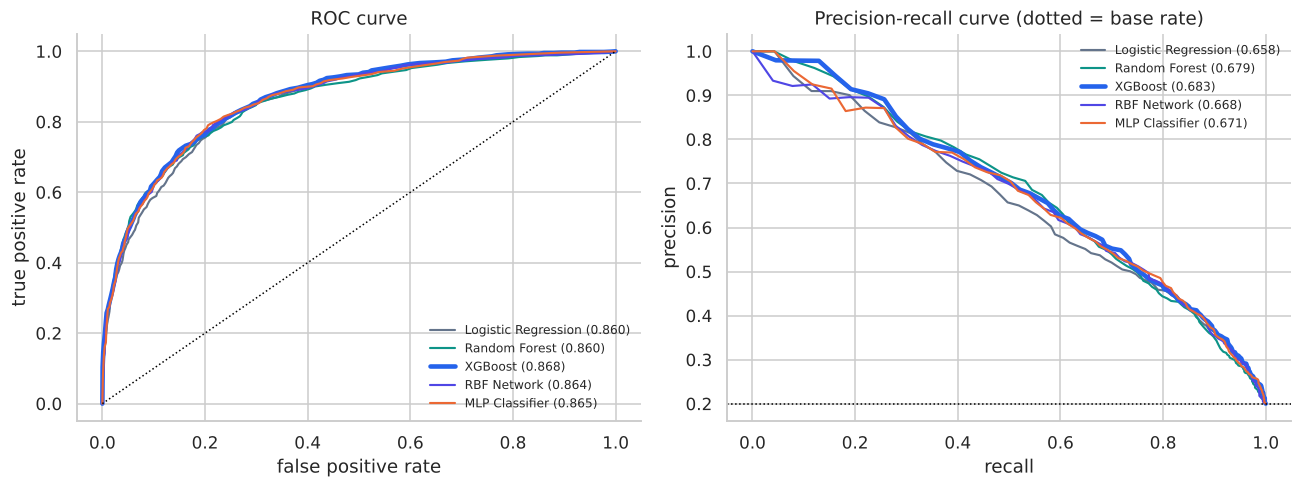

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
pal = dict(zip(metrics["models"], ["#64748b", "#0d9488", "#2563eb", "#4f46e5", "#eb6834"]))
for n, r in metrics["models"].items():
    lw = 3 if n == metrics["selected_model"] else 1.4
    ax[0].plot(r["test"]["roc_curve"]["fpr"], r["test"]["roc_curve"]["tpr"], lw=lw, color=pal[n], label=f"{n} ({r['test']['roc_auc']:.3f})")
    ax[1].plot(r["test"]["pr_curve"]["recall"], r["test"]["pr_curve"]["precision"], lw=lw, color=pal[n], label=f"{n} ({r['test']['pr_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set(title="ROC curve", xlabel="false positive rate", ylabel="true positive rate")
ax[1].axhline(res["data"]["test"].high_value.mean(), color="k", ls=":", lw=1); ax[1].set(title="Precision-recall curve (dotted = base rate)", xlabel="recall", ylabel="precision")
for a in ax: a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

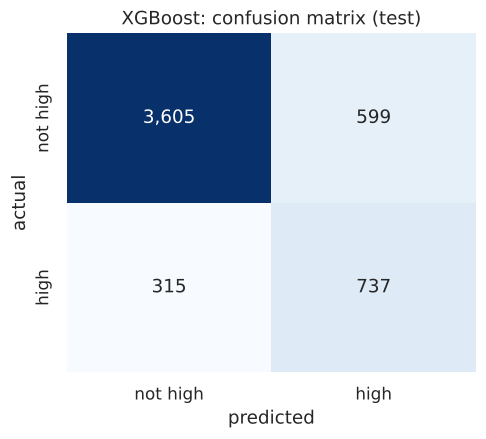

flagged 1,336 customers: 737 truly high value (precision 55%); missed 315 (recall 70%).


In [8]:
sel = metrics["selected_model"]; cm = np.array(metrics["models"][sel]["test"]["confusion_matrix"])
fig, ax = plt.subplots(figsize=(4.8, 4)); sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, xticklabels=["not high", "high"], yticklabels=["not high", "high"], ax=ax)
ax.set(title=f"{sel}: confusion matrix (test)", xlabel="predicted", ylabel="actual"); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"flagged {tp+fp:,} customers: {tp:,} truly high value (precision {tp/(tp+fp):.0%}); missed {fn:,} (recall {tp/(tp+fn):.0%}).")

**Business translation.** A confusion matrix has four cells: true positives (right flags), false positives (wasted outreach), false negatives (missed opportunities), true negatives. The decision threshold moves the balance between wasted outreach and missed opportunities - choose it from the *cost* of each mistake, not from a default of 0.5.

## 5. The RBF network under the microscope
The RBF network is built from scratch in `src/models/rbf_network.py`. The key hyper-parameter `gamma` is the **width of each Gaussian**: large gamma = each prototype only "sees" very close customers (risk of overfitting); small gamma = wide, smooth, blurry (risk of underfitting).

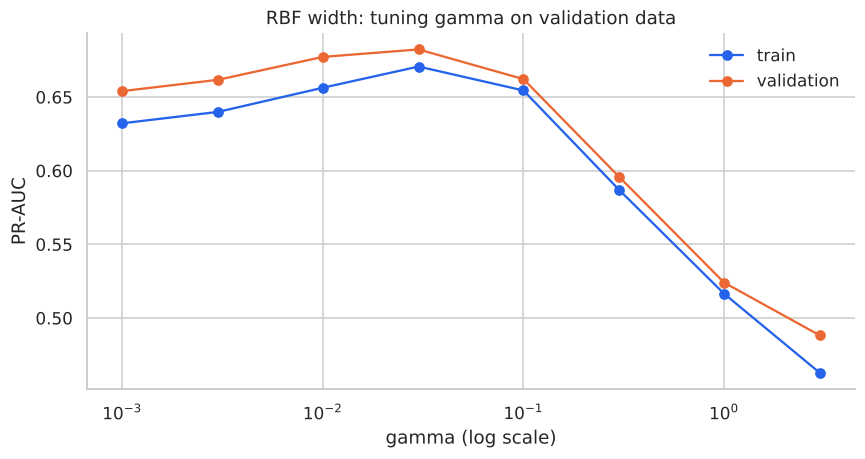

,gamma,train PR-AUC,validation PR-AUC
0,0.00,0.63,0.65
1,0.00,0.64,0.66
2,0.01,0.66,0.68
3,0.03,0.67,0.68
4,0.10,0.65,0.66
5,0.30,0.59,0.60
6,1.00,0.52,0.52
7,3.00,0.46,0.49


In [9]:
ytr, yva = train.high_value.to_numpy(), val.high_value.to_numpy()
gammas = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
out = []
for g in gammas:
    m = RBFNetworkClassifier(n_centers=25, gamma=g, C=1.0, random_state=RANDOM_STATE).fit(Xtr, ytr)
    out.append({"gamma": g, "train PR-AUC": average_precision_score(ytr, m.predict_proba(Xtr)[:, 1]), "validation PR-AUC": average_precision_score(yva, m.predict_proba(Xva)[:, 1])})
gam = pd.DataFrame(out)
fig, ax = plt.subplots(); ax.semilogx(gam.gamma, gam["train PR-AUC"], "o-", label="train", color="#2563eb"); ax.semilogx(gam.gamma, gam["validation PR-AUC"], "o-", label="validation", color="#eb6834")
ax.set(xlabel="gamma (log scale)", ylabel="PR-AUC", title="RBF width: tuning gamma on validation data"); ax.legend(frameon=False); plt.show()
gam.round(3)

**What the curve actually shows (read it, do not assume it).**
* Performance peaks at a moderate `gamma` (a few hundredths) and **collapses for large gamma on both train and validation**. With `gamma` too large each Gaussian is so narrow that almost every customer is "far" from every prototype, all activations are close to 0 and the output layer has nothing to work with - this is **underfitting caused by vanishing activations**, not the classic memorisation overfit. (Overfitting would show train rising while validation falls; with only 25 centres and a regularised output layer the RBF network cannot memorise much.)
* **Validation scores sit slightly above train scores.** That is not a bug: the two windows are different periods with different customers, and the validation period happens to be a little easier to predict. A train-vs-validation gap with the *wrong* sign is a reminder that a score is only meaningful relative to the period it was measured on.
* Tuning `gamma` (and `C`) on validation data, as the pipeline does, picks the plateau at the top.

In [10]:
m = RBFNetworkClassifier(n_centers=8, gamma=0.05, C=1.0, random_state=RANDOM_STATE).fit(Xtr, ytr)
one = Xva[:1]; act = m._activations(one)[0]
print("One customer's 8 hidden-neuron activations (1 = identical to that prototype, ~0 = far away):")
print(np.round(act, 3))
print("output layer turns these into P(high value) =", round(float(m.predict_proba(one)[0, 1]), 3))

One customer's 8 hidden-neuron activations (1 = identical to that prototype, ~0 = far away):
[0.688 0.51  0.043 0.259 0.115 0.036 0.326 0.636]
output layer turns these into P(high value) = 0.032


## 6. Explainability: which features drive the prediction?

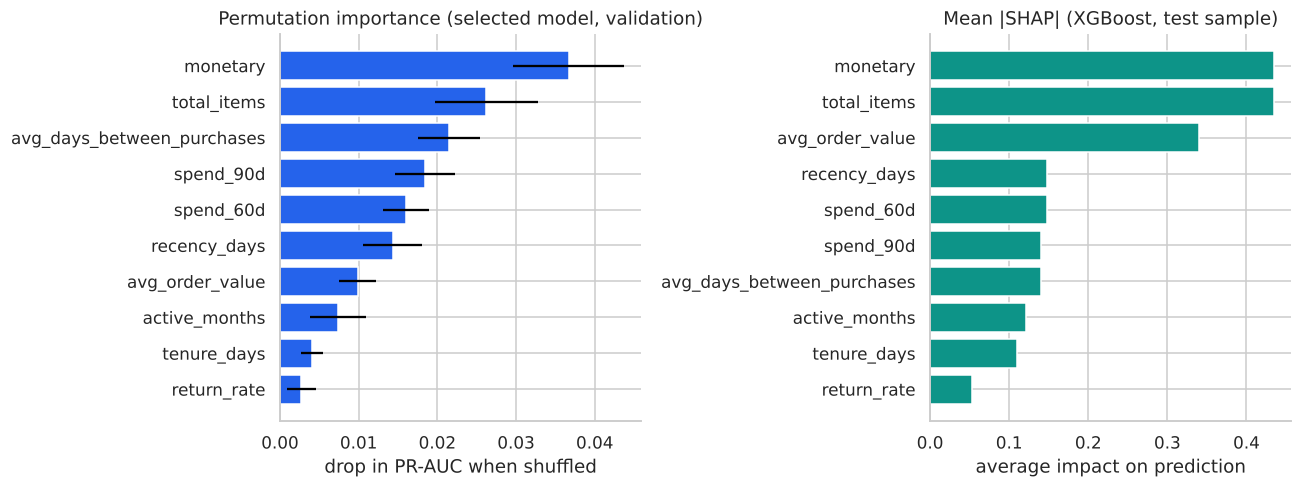

,feature,mean_abs_shap,direction_corr
0,monetary,0.44,0.85
1,total_items,0.43,0.91
2,avg_order_value,0.34,0.79
3,recency_days,0.15,-0.85
4,spend_60d,0.15,0.81
5,spend_90d,0.14,0.78
6,avg_days_between_purchases,0.14,-0.39
7,active_months,0.12,0.94


In [11]:
from src.analytics.explain import permutation_table, shap_table
perm = permutation_table(res["bundle"]["pipeline"], res["data"]["val"][FEATURE_COLUMNS], res["data"]["val"].high_value.to_numpy(), n_repeats=8)
shap_df = shap_table(res["fitted"]["XGBoost"], res["prep"], res["data"]["test"][FEATURE_COLUMNS])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
p = perm.head(10).iloc[::-1]; ax[0].barh(p.feature, p.importance, xerr=p["std"], color="#2563eb"); ax[0].set(title="Permutation importance (selected model, validation)", xlabel="drop in PR-AUC when shuffled")
if shap_df is not None:
    s = shap_df.head(10).iloc[::-1]; ax[1].barh(s.feature, s.mean_abs_shap, color="#0d9488"); ax[1].set(title="Mean |SHAP| (XGBoost, test sample)", xlabel="average impact on prediction")
plt.tight_layout(); plt.show()
if shap_df is not None: display(shap_df.head(8).round(3))

* **Permutation importance** shuffles one feature and measures how much the score falls: a big drop = the model relied on it.
* **SHAP** splits each single prediction into per-feature contributions. `direction_corr` > 0 means "higher value of this feature pushes the prediction *up*"; for `recency_days` a *negative* sign is expected (longer since last order -> lower chance).
* Both are about *what the model uses*, not about *what causes* value.

## Check yourself
1. Why would a random 80/20 split of customers overstate performance here?
2. The test set has a higher GBP threshold than training. Is the model broken?
3. You can only contact 500 customers. How would you choose the threshold?